In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# La desocupación desde 2007

La serie mensual de la tasa de desocupación del total nacional, y por qué hay que tener cuidado al
compararla entre marcos muestrales.

In [2]:
import dane_data as dd

serie = dd.geih.serie_indicadores(range(2007, 2027), anual=False)
serie["fecha"] = pd.to_datetime(serie[["anio", "mes"]].rename(columns={"anio": "year", "mes": "month"}).assign(day=1))
serie["marco"] = [dd.geih.marco_muestral(a) for a in serie["anio"]]
serie[["fecha", "marco", "tgp", "to", "td"]].tail()

,fecha,marco,tgp,to,td
231,2026-04-01,CNPV 2018,64.741220,59.055998,8.781457
232,2026-05-01,CNPV 2018,64.942657,59.733833,8.020651
233,2026-06-01,CNPV 2018,64.543037,59.362215,8.026926
234,2026-07-01,CNPV 2018,64.768526,59.519311,8.104578
235,2026-08-01,CNPV 2018,63.289540,57.363310,9.363680


{dd}`geih.serie_indicadores()` calcula un año a la vez y guarda el resultado: veinte años sin cargar los
microdatos en memoria. {dd}`geih.marco_muestral()` dice con qué proyecciones de población se expandió cada
año.

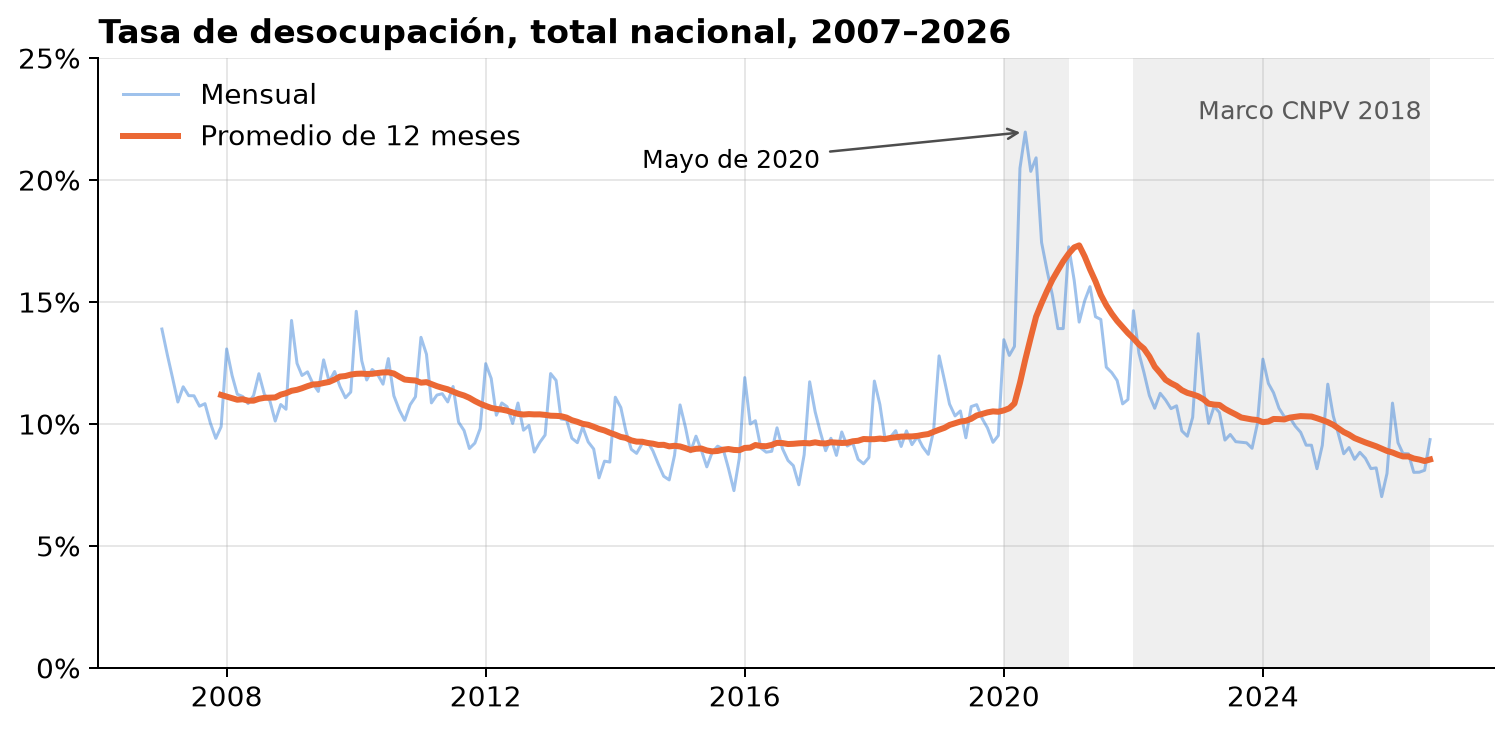

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(serie["fecha"], serie["td"], lw=1.2, alpha=0.45, label="Mensual")
ax.plot(serie["fecha"], serie["td"].rolling(12).mean(), lw=2.4, label="Promedio de 12 meses")
for inicio, fin in [("2020-01-01", "2020-12-31"), ("2022-01-01", serie["fecha"].max())]:
    ax.axvspan(pd.Timestamp(inicio), pd.Timestamp(fin), color="0.5", alpha=0.12, lw=0)
ax.text(pd.Timestamp("2023-01-01"), 22.5, "Marco CNPV 2018", color="0.35", fontsize=10)
ax.annotate("Mayo de 2020", xy=(pd.Timestamp("2020-05-01"), serie.set_index("fecha").loc["2020-05-01", "td"]),
            xytext=(pd.Timestamp("2014-06-01"), 20.5), arrowprops={"arrowstyle": "->", "color": "0.3"}, fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 25)
ax.set_title("Tasa de desocupación, total nacional, 2007–2026")
ax.legend(loc="upper left");

La desocupación bajó de entre 11 % y 12 % en 2007–2010 a entre 8,9 % y 10,5 % en 2014–2019, saltó al 22 % en
mayo de 2020 con la pandemia y bajó del 10 % en 2025. La estacionalidad es fuerte: todos los años salvo
2020, enero es el mes con más desocupación.

## Años completos

In [4]:
anual = dd.geih.serie_indicadores(range(2007, 2026))
anual["marco"] = [dd.geih.marco_muestral(a) for a in anual["anio"]]
anual[["anio", "marco", "tgp", "to", "td"]].round(1)

,anio,marco,tgp,to,td
0,2007,censo 2005,58.3,51.8,11.2
1,2008,censo 2005,58.5,51.9,11.3
2,2009,censo 2005,61.3,53.9,12.0
3,2010,censo 2005,62.7,55.4,11.8
4,2011,censo 2005,63.7,56.8,10.8
5,2012,censo 2005,64.5,57.8,10.4
6,2013,censo 2005,64.2,58.0,9.6
7,2014,censo 2005,64.2,58.4,9.1
8,2015,censo 2005,64.7,59.0,8.9
9,2016,censo 2005,64.5,58.5,9.2


## Dos marcos, dos niveles

Los años 2010–2020 existen en las dos versiones: la serie principal (marco del censo 2005, salvo 2020) y la
**serie de empalme** (marco del CNPV 2018, PET de 15 años o más). La tasa de desocupación cambia poco entre
una y otra, pero la participación sí, porque cambian la población y la edad mínima de la PET:

In [5]:
principal = dd.geih.serie_indicadores(range(2010, 2021))
empalme = dd.geih.serie_indicadores(range(2010, 2021), empalme=True)
comparacion = principal[["anio", "tgp", "td"]].merge(empalme[["anio", "tgp", "td"]], on="anio",
                                                    suffixes=("_principal", "_empalme"))
comparacion.round(1)

,anio,tgp_principal,td_principal,tgp_empalme,td_empalme
0,2010,62.7,11.8,67.7,12.0
1,2011,63.7,10.8,68.1,11.1
2,2012,64.5,10.4,68.6,10.6
3,2013,64.2,9.6,67.8,9.9
4,2014,64.2,9.1,67.4,9.4
5,2015,64.7,8.9,67.5,9.2
6,2016,64.5,9.2,66.9,9.5
7,2017,64.4,9.4,66.4,9.7
8,2018,64.0,9.7,65.7,10.0
9,2019,63.3,10.5,64.8,10.9


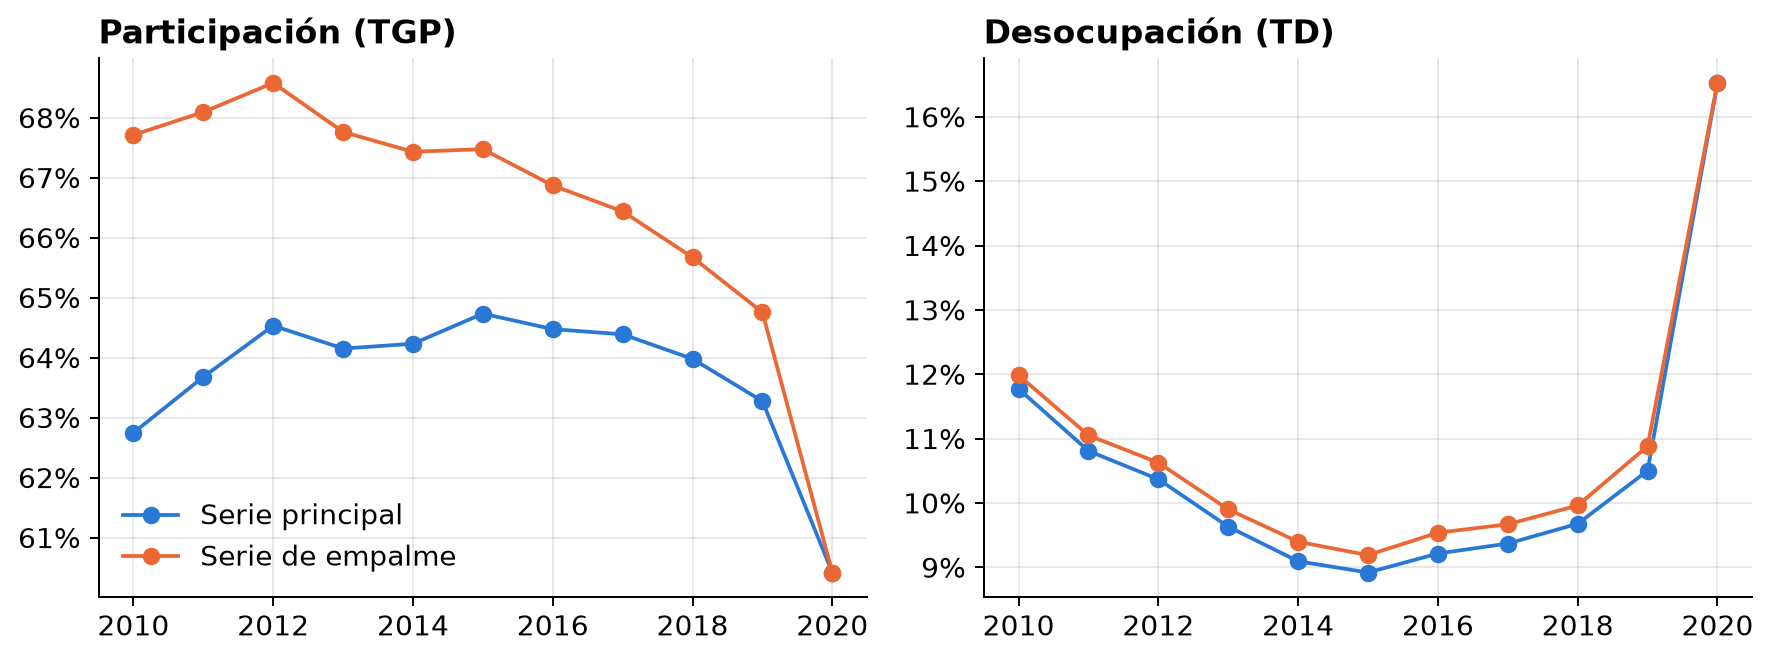

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, tasa, titulo in zip(axes, ["tgp", "td"], ["Participación (TGP)", "Desocupación (TD)"]):
    ax.plot(comparacion["anio"], comparacion[f"{tasa}_principal"], marker="o", label="Serie principal")
    ax.plot(comparacion["anio"], comparacion[f"{tasa}_empalme"], marker="o", label="Serie de empalme")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_title(titulo)
axes[0].legend()
fig.tight_layout();

Para una serie larga comparable con los años recientes, use la serie de empalme hasta 2020 y la principal
desde 2022:

In [7]:
comparable = pd.concat([
    dd.geih.serie_indicadores(range(2010, 2021), empalme=True),
    dd.geih.serie_indicadores(range(2022, 2026)),
], ignore_index=True)
comparable[["anio", "tgp", "to", "td"]].round(1)

,anio,tgp,to,td
0,2010,67.7,59.6,12.0
1,2011,68.1,60.6,11.1
2,2012,68.6,61.3,10.6
3,2013,67.8,61.1,9.9
4,2014,67.4,61.1,9.4
5,2015,67.5,61.3,9.2
6,2016,66.9,60.5,9.5
7,2017,66.4,60.0,9.7
8,2018,65.7,59.1,10.0
9,2019,64.8,57.7,10.9


```{seealso}
* {doc}`../guia/encuestas`: marcos muestrales y serie de empalme.
* {doc}`validacion`: estas cifras frente a las que publica el DANE.
```